# 02 – Khám phá dữ liệu (EDA)

**Phần 1:** Phân phối biến mục tiêu `Appliances` và giá trị ngoại lệ.

**Phần 2:** Xu hướng tiêu thụ theo thời gian (giờ, ngày trong tuần, theo tuần).

**Phần 3:** Tương quan với biến mục tiêu và đa cộng tuyến giữa các đặc trưng.

**Phần 4:** Ngoại lệ ở các biến đầu vào và kết luận cho bước tiền xử lý.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import TARGET
from src.data_loader import load_raw_data
from src.visualization import save_fig, set_style

set_style()
df = load_raw_data()
y = df[TARGET]
df.shape

(19735, 29)

## Phần 1. Phân phối biến mục tiêu
### 1.1 Histogram và boxplot

Đã lưu hình: reports/figures/02_target_distribution.png


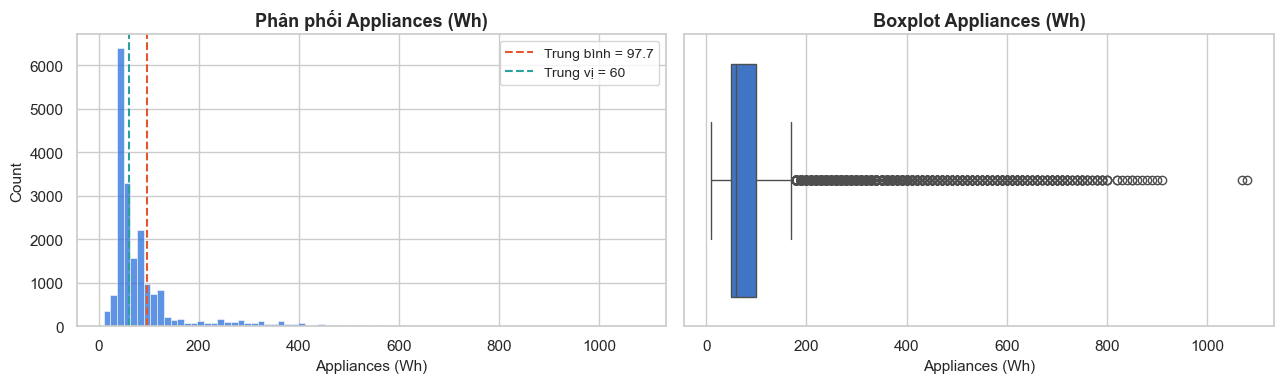

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y, bins=80, ax=axes[0])
axes[0].axvline(y.mean(), color="#e4572e", linestyle="--", label=f"Trung bình = {y.mean():.1f}")
axes[0].axvline(y.median(), color="#29a19c", linestyle="--", label=f"Trung vị = {y.median():.0f}")
axes[0].set_title("Phân phối Appliances (Wh)")
axes[0].set_xlabel("Appliances (Wh)")
axes[0].legend()

sns.boxplot(x=y, ax=axes[1])
axes[1].set_title("Boxplot Appliances (Wh)")
axes[1].set_xlabel("Appliances (Wh)")
fig.tight_layout()
save_fig(fig, "02_target_distribution")
plt.show()

In [3]:
print("Skewness:", round(y.skew(), 2))
y.quantile([0.5, 0.75, 0.9, 0.95, 0.99]).to_frame("Wh")

Skewness: 3.39


,Wh
0.50,60.0
0.75,100.0
0.90,196.0
0.95,330.0
0.99,576.6


**Nhận xét:**
- Phân phối **lệch phải rất mạnh** (skewness ≈ 3.4): phần lớn thời gian thiết bị tiêu thụ 40–100 Wh,
  nhưng có đuôi dài tới 1080 Wh.
- Trung bình (~98 Wh) lớn hơn hẳn trung vị (60 Wh) do bị các đỉnh cao kéo lên.
- 90% mẫu ≤ 196 Wh, nhưng 1% mẫu cao nhất vượt 576 Wh.

### 1.2 Giá trị ngoại lệ theo quy tắc IQR

In [4]:
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
n_out = (y > upper).sum()
print(f"Q1 = {q1:.0f}, Q3 = {q3:.0f}, IQR = {iqr:.0f}")
print(f"Ngưỡng trên = {upper:.0f} Wh")
print(f"Số mẫu vượt ngưỡng: {n_out} ({n_out / len(y):.2%})")

Q1 = 50, Q3 = 100, IQR = 50
Ngưỡng trên = 175 Wh
Số mẫu vượt ngưỡng: 2138 (10.83%)


**Quyết định xử lý ngoại lệ:**
- Có ~10,8% mẫu vượt ngưỡng IQR (175 Wh). Tỷ lệ này **quá lớn** để coi là lỗi đo.
- Về bản chất vật lý, các giá trị này là **những lúc nhiều thiết bị cùng hoạt động** (nấu ăn, giặt, ...),
  chính là hiện tượng mô hình cần dự đoán.
- → **Không xóa** ngoại lệ ở biến mục tiêu. Thay vào đó xem xét **biến đổi log** để giảm ảnh hưởng của đuôi dài
  khi huấn luyện, và báo cáo thêm **MAE** (ít nhạy với ngoại lệ hơn RMSE).

### 1.3 Biến đổi log1p

Đã lưu hình: reports/figures/02_target_log_transform.png


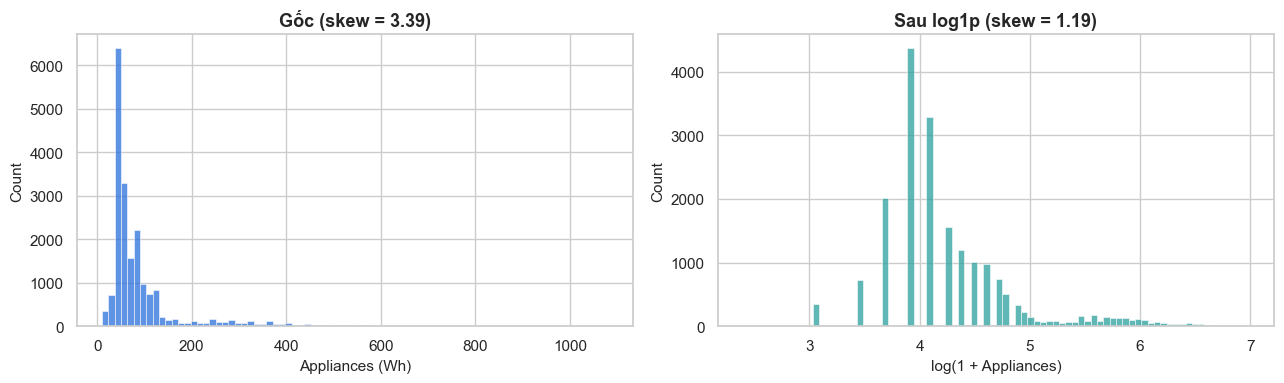

In [5]:
y_log = np.log1p(y)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y, bins=80, ax=axes[0])
axes[0].set_title(f"Gốc (skew = {y.skew():.2f})")
axes[0].set_xlabel("Appliances (Wh)")
sns.histplot(y_log, bins=80, ax=axes[1], color="#29a19c")
axes[1].set_title(f"Sau log1p (skew = {y_log.skew():.2f})")
axes[1].set_xlabel("log(1 + Appliances)")
fig.tight_layout()
save_fig(fig, "02_target_log_transform")
plt.show()

**Nhận xét:** Sau `log1p`, độ lệch giảm từ ~3.39 xuống ~1.19 – phân phối cân đối hơn nhiều.
Nhóm sẽ thực nghiệm huấn luyện mô hình trên `log1p(Appliances)` rồi đổi ngược (`expm1`) khi đánh giá,
để metric vẫn tính trên đơn vị Wh gốc và so sánh công bằng với mô hình không dùng log.

### 1.4 Biến `lights`

In [6]:
print("Tỷ lệ lights = 0:", f"{(df['lights'] == 0).mean():.1%}")
print("Tương quan lights – Appliances:", round(df["lights"].corr(y), 3))
df["lights"].value_counts().sort_index().to_frame("số mẫu")

Tỷ lệ lights = 0: 77.3%
Tương quan lights – Appliances: 0.197


,số mẫu
lights,
0,15252
10,2212
20,1624
30,559
40,77
50,9
60,1
70,1


`lights` bằng 0 trong ~77% thời gian và chỉ nhận vài giá trị rời rạc (0, 10, 20, ...). Tương quan với
`Appliances` dương nhưng yếu (~0.2). Đây là tín hiệu "có người đang ở nhà/hoạt động", nên vẫn giữ làm đặc trưng.

## Phần 2. Xu hướng theo thời gian
Dùng hàm `add_time_features` trong `src/features.py` để trích xuất giờ, thứ trong tuần.

In [7]:
from src.features import add_time_features

dft = add_time_features(df)
DAY_NAMES = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]

### 2.1 Tiêu thụ trung bình theo giờ trong ngày

Đã lưu hình: reports/figures/02_by_hour.png


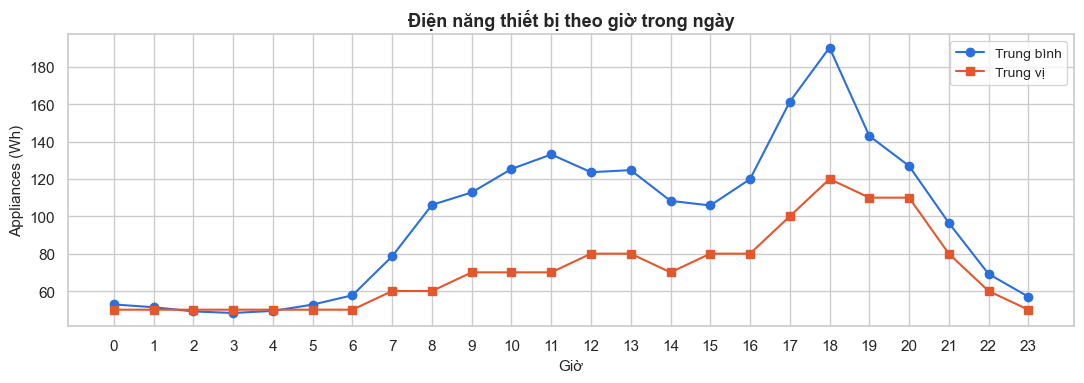

In [8]:
by_hour = dft.groupby("hour")[TARGET].agg(["mean", "median"])
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(by_hour.index, by_hour["mean"], marker="o", label="Trung bình")
ax.plot(by_hour.index, by_hour["median"], marker="s", label="Trung vị")
ax.set_xticks(range(24))
ax.set_title("Điện năng thiết bị theo giờ trong ngày")
ax.set_xlabel("Giờ")
ax.set_ylabel("Appliances (Wh)")
ax.legend()
fig.tight_layout()
save_fig(fig, "02_by_hour")
plt.show()

**Nhận xét:**
- Ban đêm (0h–6h) tiêu thụ thấp và ổn định (~50 Wh) – chỉ còn các thiết bị nền như tủ lạnh.
- Tăng mạnh từ 7h, đạt đỉnh phụ quanh 11h (~133 Wh) và **đỉnh chính lúc 18h (~190 Wh)** – giờ nấu ăn tối.
- Giờ trong ngày là đặc trưng rất mạnh → cần đưa vào mô hình (qua `hour`/`nsm` và mã hóa chu kỳ sin/cos).

### 2.2 Theo thứ trong tuần

Đã lưu hình: reports/figures/02_by_weekday.png


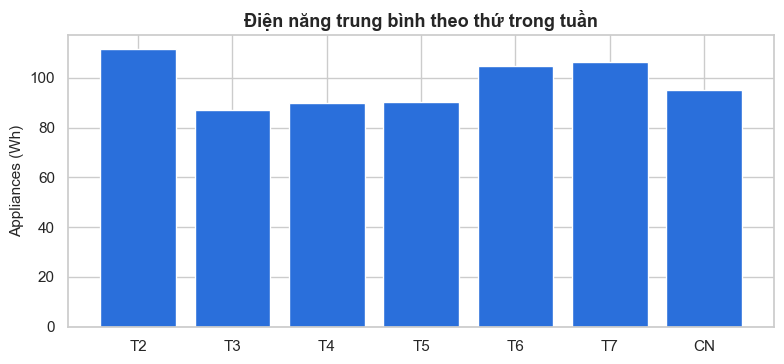

is_weekend
Ngày thường     96.6
Cuối tuần      100.6
Name: Appliances, dtype: float64


In [9]:
by_day = dft.groupby("day_of_week")[TARGET].mean()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(DAY_NAMES, by_day.values)
ax.set_title("Điện năng trung bình theo thứ trong tuần")
ax.set_ylabel("Appliances (Wh)")
fig.tight_layout()
save_fig(fig, "02_by_weekday")
plt.show()
print(dft.groupby("is_weekend")[TARGET].mean().rename({0: "Ngày thường", 1: "Cuối tuần"}).round(1))

**Nhận xét:** Chênh lệch giữa các thứ nhỏ hơn nhiều so với chênh lệch giữa các giờ. Thứ Hai cao nhất (~112 Wh),
Thứ Ba–Thứ Năm thấp nhất (~87–90 Wh); trung bình cuối tuần (~101 Wh) chỉ cao hơn ngày thường (~97 Wh) một chút.
→ `day_of_week` có thể có ích nhưng yếu hơn `hour`; mô hình sẽ cho biết qua feature importance.

### 2.3 Heatmap giờ × thứ

Đã lưu hình: reports/figures/02_heatmap_hour_weekday.png


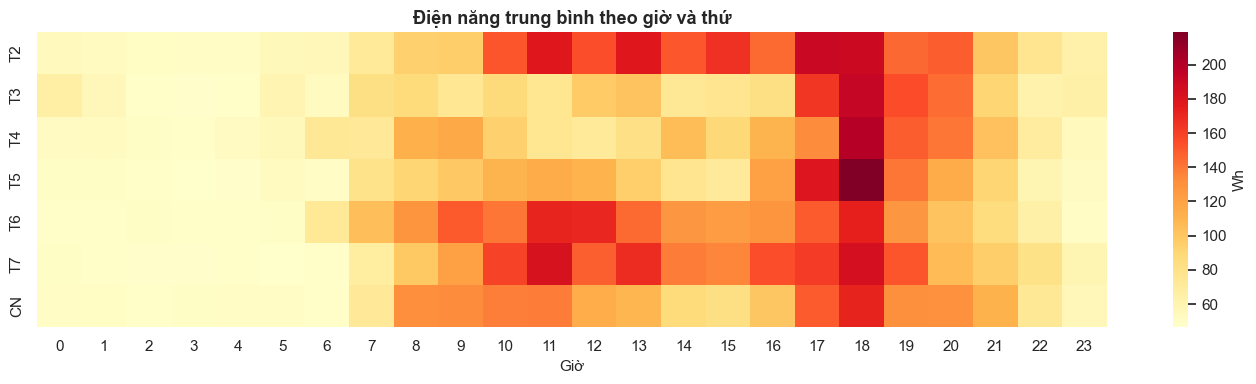

In [10]:
pivot = dft.pivot_table(index="day_of_week", columns="hour", values=TARGET, aggfunc="mean")
pivot.index = DAY_NAMES
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(pivot, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Wh"})
ax.set_title("Điện năng trung bình theo giờ và thứ")
ax.set_xlabel("Giờ")
ax.set_ylabel("")
fig.tight_layout()
save_fig(fig, "02_heatmap_hour_weekday")
plt.show()

**Nhận xét:** Heatmap xác nhận mô hình "ngủ – thức": dải tối ở ban đêm cho mọi thứ trong tuần, các ô nóng tập
trung vào chiều tối 17h–20h. Cuối tuần, mức tiêu thụ ban ngày (10h–15h) có xu hướng cao hơn vì gia đình ở nhà.

### 2.4 Xu hướng dài hạn theo tuần

Đã lưu hình: reports/figures/02_weekly_trend.png


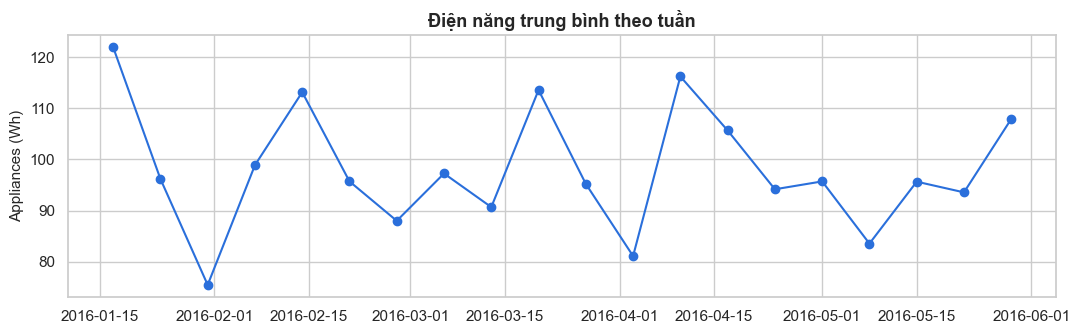

In [11]:
weekly = df.set_index("date")[TARGET].resample("W").mean()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(weekly.index, weekly.values, marker="o")
ax.set_title("Điện năng trung bình theo tuần")
ax.set_ylabel("Appliances (Wh)")
fig.tight_layout()
save_fig(fig, "02_weekly_trend")
plt.show()

**Nhận xét:** Trung bình theo tuần dao động 75–122 Wh, **không có xu hướng tăng/giảm rõ rệt** trong 4,5 tháng.
Điều này thuận lợi cho việc chia train/test theo thời gian: phân phối tập test không lệch quá xa tập train.

## Tóm tắt EDA (phần 1–2)
| Phát hiện | Hệ quả cho mô hình |
|---|---|
| Biến mục tiêu lệch phải mạnh, ~10,8% ngoại lệ theo IQR | Không xóa ngoại lệ; thử biến đổi `log1p`; báo cáo cả MAE và RMSE |
| Chu kỳ ngày rất rõ (đỉnh 18h) | Dùng đặc trưng giờ + mã hóa sin/cos |
| Khác biệt theo thứ nhỏ | Giữ `day_of_week`, `is_weekend`; kiểm chứng bằng feature importance |
| Không có xu hướng dài hạn | Chia dữ liệu theo thời gian là hợp lý |

## Phần 3. Tương quan giữa các biến
### 3.1 Tương quan của từng đặc trưng với biến mục tiêu
So sánh hai hệ số:
- **Pearson**: đo quan hệ **tuyến tính**, nhạy với ngoại lệ.
- **Spearman**: đo quan hệ **đơn điệu** (tăng/giảm cùng chiều, không cần thẳng), dựa trên thứ hạng nên ít bị
  ngoại lệ chi phối.

In [12]:
num = dft.drop(columns=["date", "rv2", "hour"])
corr_target = pd.DataFrame({
    "pearson": num.corr(method="pearson")[TARGET],
    "spearman": num.corr(method="spearman")[TARGET],
}).drop(TARGET)
corr_target = corr_target.reindex(corr_target["spearman"].abs().sort_values(ascending=False).index)
corr_target.round(3).head(12)

,pearson,spearman
hour_sin,-0.260,-0.461
nsm,0.217,0.416
T2,0.120,0.305
lights,0.197,0.302
RH_out,-0.152,-0.269
hour_cos,-0.204,-0.245
T1,0.055,0.244
T6,0.118,0.242
T8,0.040,0.236
RH_6,-0.083,-0.230


Đã lưu hình: reports/figures/02_corr_with_target.png


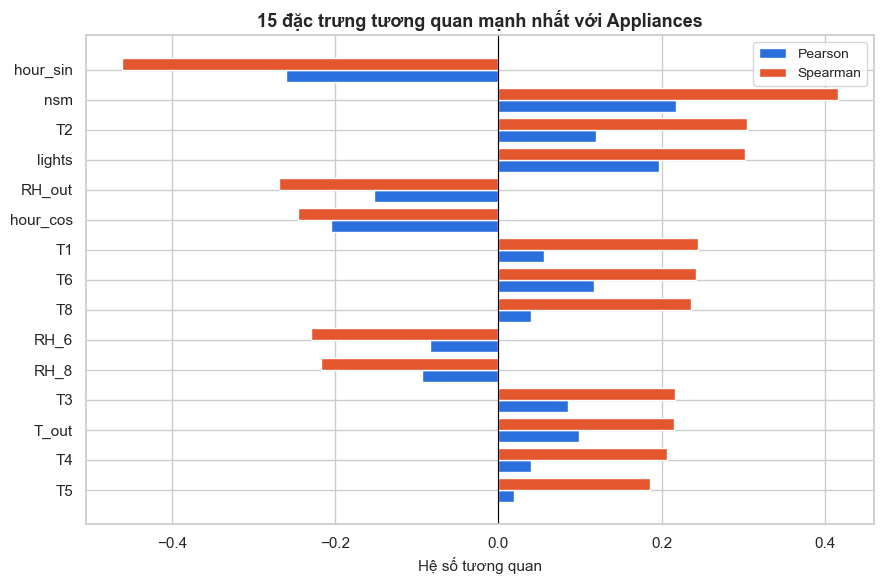

In [13]:
top = corr_target.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
yy = np.arange(len(top))
ax.barh(yy - 0.2, top["pearson"], height=0.4, label="Pearson")
ax.barh(yy + 0.2, top["spearman"], height=0.4, label="Spearman")
ax.set_yticks(yy)
ax.set_yticklabels(top.index)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("15 đặc trưng tương quan mạnh nhất với Appliances")
ax.set_xlabel("Hệ số tương quan")
ax.legend()
fig.tight_layout()
save_fig(fig, "02_corr_with_target")
plt.show()

In [14]:
print("rv1 – Pearson:", round(corr_target.loc["rv1", "pearson"], 3),
      "| Spearman:", round(corr_target.loc["rv1", "spearman"], 3))

rv1 – Pearson: -0.011 | Spearman: -0.009


**Nhận xét:**
- **Không có đặc trưng nào tương quan tuyến tính mạnh** với `Appliances`: |Pearson| lớn nhất chỉ ≈ 0,26
  (`hour_sin`). Hầu hết cảm biến có |r| < 0,15.
- Hệ số **Spearman cao hơn Pearson khá rõ** (vd. `hour_sin` −0,46; `T2` 0,31; `lights` 0,30) → quan hệ có tính
  **đơn điệu nhưng phi tuyến**, và bị các đỉnh ngoại lệ làm yếu đi khi đo tuyến tính.
- Các đặc trưng **thời gian** đứng đầu, sau đó là `lights`, `T2` (phòng khách), `RH_out`, `T1` (bếp), `T6`.
- `rv1` gần như bằng 0 với cả hai hệ số – đúng kỳ vọng với một biến ngẫu nhiên.
- **Hệ quả:** mô hình tuyến tính khó đạt kết quả cao; mô hình phi tuyến (cây, ensemble) có khả năng tốt hơn.
  Đây là giả thuyết cho **RQ2**, sẽ kiểm chứng bằng thực nghiệm.

### 3.2 Tương quan giữa các đặc trưng đầu vào (đa cộng tuyến)

Đã lưu hình: reports/figures/02_corr_heatmap_inputs.png


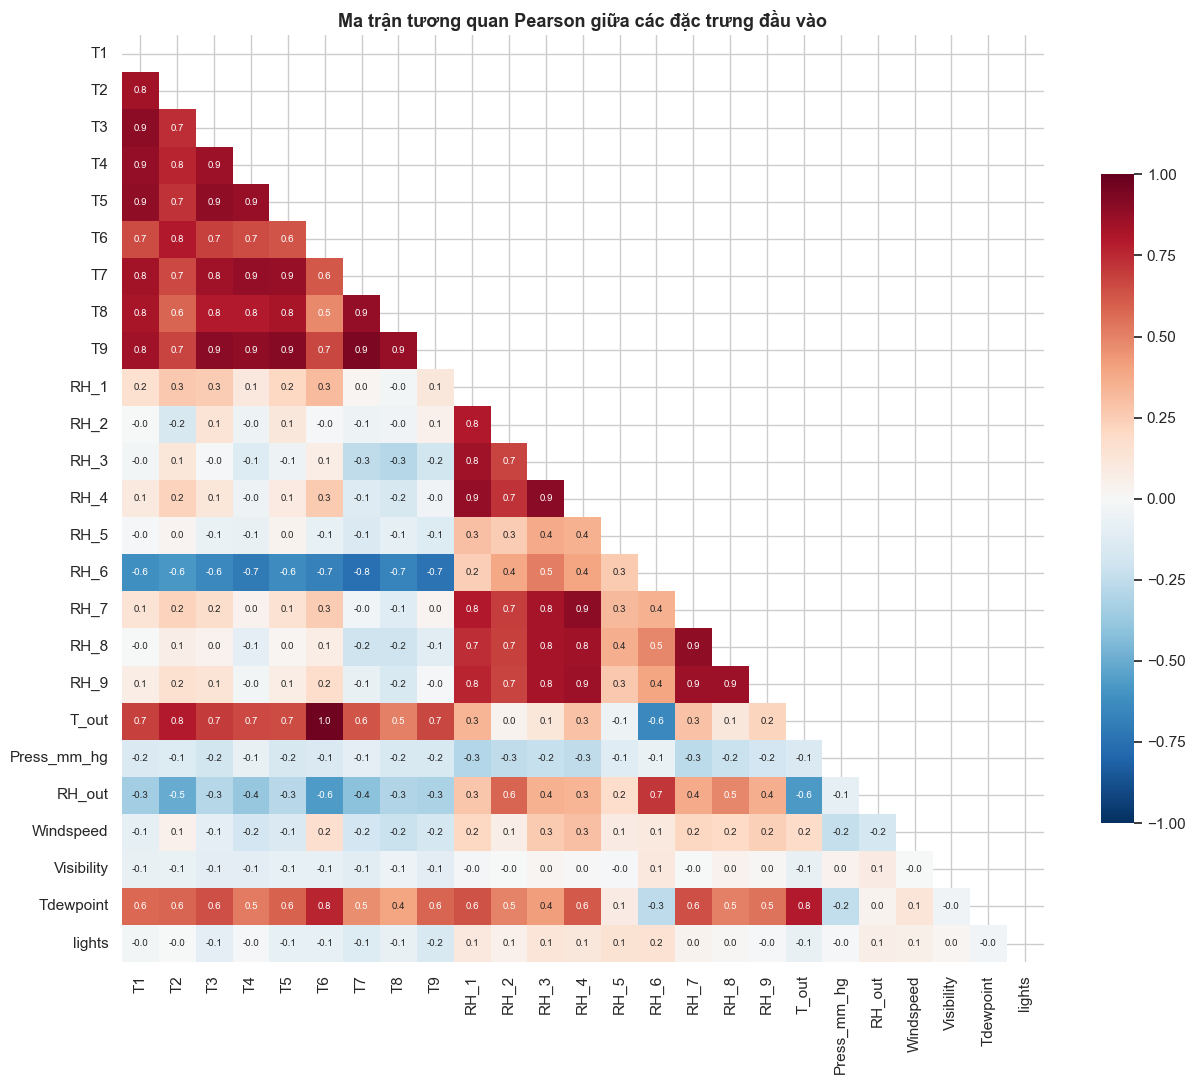

In [15]:
from src.config import HUMIDITY_COLS, TEMP_COLS, WEATHER_COLS

input_cols = TEMP_COLS + HUMIDITY_COLS + WEATHER_COLS + ["lights"]
corr_in = df[input_cols].corr()

fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr_in, dtype=bool))
sns.heatmap(corr_in, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Ma trận tương quan Pearson giữa các đặc trưng đầu vào")
fig.tight_layout()
save_fig(fig, "02_corr_heatmap_inputs")
plt.show()

In [16]:
pairs = (corr_in.where(np.triu(np.ones_like(corr_in, dtype=bool), k=1))
         .stack().rename("r").reset_index())
pairs["|r|"] = pairs["r"].abs()
pairs.sort_values("|r|", ascending=False).head(10).round(3)

,level_0,level_1,r,|r|
122,T6,T_out,0.975,0.975
130,T7,T9,0.945,0.945
93,T5,T9,0.911,0.911
52,T3,T9,0.901,0.901
209,RH_3,RH_4,0.899,0.899
224,RH_4,RH_7,0.894,0.894
1,T1,T3,0.892,0.892
73,T4,T9,0.889,0.889
48,T3,T5,0.888,0.888
3,T1,T5,0.885,0.885


### 3.3 Hệ số phóng đại phương sai (VIF)
VIF của đặc trưng $j$: $VIF_j = \frac{1}{1 - R_j^2}$, với $R_j^2$ là R² khi hồi quy đặc trưng $j$ theo tất cả
đặc trưng còn lại. Quy ước thường dùng: VIF > 10 là đa cộng tuyến nghiêm trọng.

Tính nhanh: VIF chính là đường chéo của nghịch đảo ma trận tương quan.

In [17]:
vif = pd.Series(np.diag(np.linalg.inv(corr_in.values)), index=input_cols, name="VIF")
vif = vif.sort_values(ascending=False).round(1)
print("Số đặc trưng có VIF > 10:", (vif > 10).sum(), "/", len(vif))
vif.to_frame().head(12)

Số đặc trưng có VIF > 10: 14 / 25


,VIF
T_out,146.8
Tdewpoint,86.1
RH_out,49.2
T6,33.5
T2,28.8
T9,28.3
RH_2,21.9
T1,19.7
T7,17.5
RH_4,17.1


**Nhận xét:**
- Có **22 cặp đặc trưng với |r| > 0,85**, chủ yếu giữa các **nhiệt độ** với nhau và giữa các **độ ẩm** với nhau, cặp mạnh nhất là `T6` – `T_out`
  (r ≈ 0,975): `T6` là cảm biến **bên ngoài** nhà nên gần như đo cùng đại lượng với trạm thời tiết.
  `T9` cũng gần trùng với `T3`, `T5`, `T7` (r > 0,9).
- **14/25 đặc trưng có VIF > 10**, cao nhất `T_out` (~147) và `Tdewpoint` (~86, vì điểm sương được tính từ nhiệt độ
  và độ ẩm).
- **Ảnh hưởng:**
  - Hồi quy tuyến tính thường: hệ số không ổn định, khó diễn giải → dùng **Ridge/Lasso** (có regularization)
    và **chuẩn hóa** dữ liệu trước khi huấn luyện.
  - Mô hình cây (Random Forest, Gradient Boosting): ít bị ảnh hưởng về độ chính xác, nhưng **feature importance
    bị chia sẻ** giữa các biến tương quan → khi diễn giải sẽ dùng thêm **permutation importance** và gom theo nhóm.
- **Quyết định:** **chưa loại bỏ** đặc trưng nào chỉ vì tương quan cao (có thể mỗi phòng vẫn mang thông tin riêng về
  hoạt động của người ở). Việc giảm đặc trưng sẽ dựa trên kết quả thực nghiệm (Lasso, permutation importance so với `rv1`).

## Phần 4. Ngoại lệ ở các biến đầu vào và kết luận tiền xử lý
### 4.1 Tỷ lệ ngoại lệ của từng đặc trưng
Dùng hai tiêu chí: quy tắc IQR (1,5 × IQR) và |z-score| > 3. Đồng thời kiểm tra **khoảng giá trị có hợp lý về
mặt vật lý** không (độ ẩm 0–100%, nhiệt độ trong nhà 10–35 °C, ...).

In [18]:
d = df[input_cols]
q1, q3 = d.quantile(0.25), d.quantile(0.75)
iqr_in = q3 - q1
out_iqr = ((d < q1 - 1.5 * iqr_in) | (d > q3 + 1.5 * iqr_in)).mean() * 100
out_z = (((d - d.mean()) / d.std()).abs() > 3).mean() * 100
outlier_table = pd.DataFrame({
    "min": d.min(), "max": d.max(),
    "% ngoại lệ IQR": out_iqr, "% |z| > 3": out_z,
}).sort_values("% ngoại lệ IQR", ascending=False).round(2)
outlier_table.head(10)

,min,max,% ngoại lệ IQR,% |z| > 3
lights,0.00,70.00,22.72,3.28
Visibility,1.00,66.00,12.78,0.19
RH_5,29.82,96.32,6.74,2.87
T2,16.10,29.86,2.77,1.04
T6,-6.06,28.29,2.61,0.50
T1,16.79,26.26,2.61,0.07
T_out,-5.00,26.10,2.21,0.47
RH_out,24.00,100.00,1.21,0.81
RH_2,20.46,56.03,1.19,0.66
Press_mm_hg,729.30,772.30,1.11,0.54


Đã lưu hình: reports/figures/02_input_outliers_boxplot.png


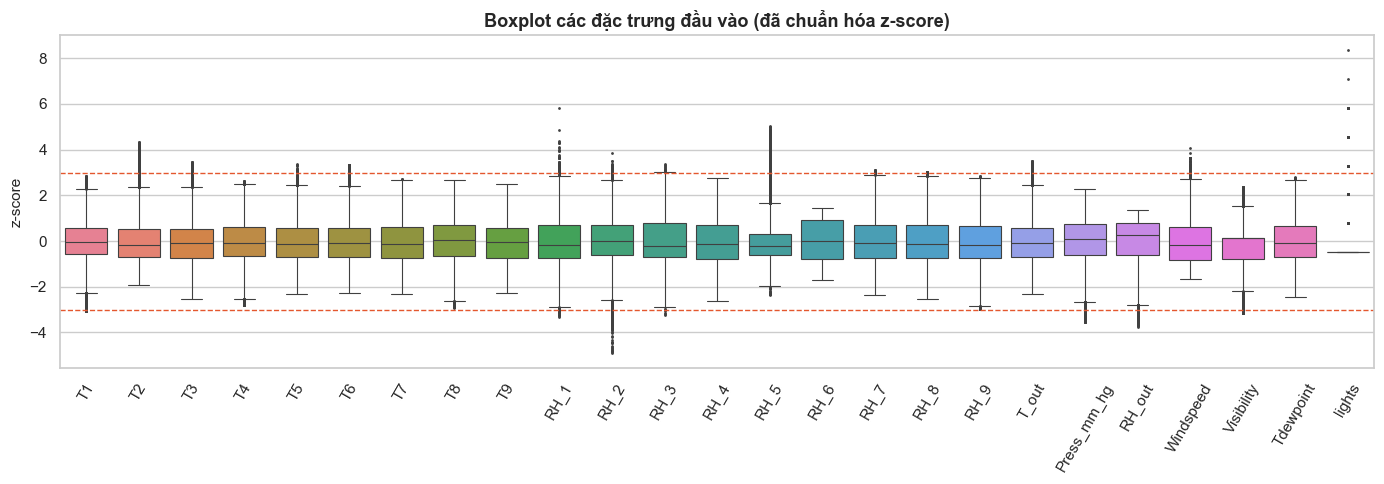

In [19]:
fig, ax = plt.subplots(figsize=(14, 5))
z_scores = (d - d.mean()) / d.std()
sns.boxplot(data=z_scores, ax=ax, fliersize=1, linewidth=0.8)
ax.axhline(3, color="#e4572e", linestyle="--", linewidth=1)
ax.axhline(-3, color="#e4572e", linestyle="--", linewidth=1)
ax.set_title("Boxplot các đặc trưng đầu vào (đã chuẩn hóa z-score)")
ax.set_ylabel("z-score")
ax.tick_params(axis="x", rotation=60)
fig.tight_layout()
save_fig(fig, "02_input_outliers_boxplot")
plt.show()

### 4.2 Xem kỹ các đặc trưng có nhiều ngoại lệ

Đã lưu hình: reports/figures/02_input_outliers_detail.png


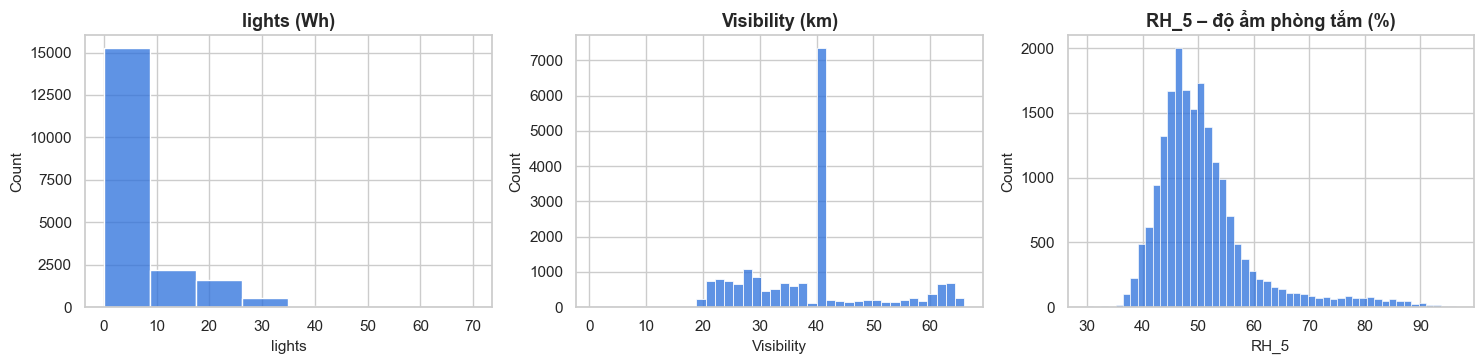

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(df["lights"], bins=8, ax=axes[0])
axes[0].set_title("lights (Wh)")
sns.histplot(df["Visibility"], bins=40, ax=axes[1])
axes[1].set_title("Visibility (km)")
sns.histplot(df["RH_5"], bins=50, ax=axes[2])
axes[2].set_title("RH_5 – độ ẩm phòng tắm (%)")
fig.tight_layout()
save_fig(fig, "02_input_outliers_detail")
plt.show()

**Nhận xét:**
- **Mọi giá trị đều nằm trong khoảng hợp lý về vật lý**: độ ẩm 1–100%, nhiệt độ trong nhà 14,9–29,9 °C, ngoài
  trời −6 → 28 °C, áp suất 729–772 mmHg. Không phát hiện giá trị lỗi cảm biến (vd. −999, độ ẩm > 100%).
- `lights` có ~23% "ngoại lệ" theo IQR chỉ vì 77% giá trị bằng 0 → IQR = 0, mọi giá trị khác 0 đều bị coi là
  ngoại lệ. Đây là đặc điểm của biến rời rạc, **không phải** lỗi.
- `Visibility` (~13%): trạm thời tiết ghi phần lớn là 40 km, các giá trị thấp ứng với ngày sương mù/mưa – thật.
- `RH_5` (độ ẩm phòng tắm, ~7%): các đỉnh 80–96% là lúc **tắm** – chính là dấu hiệu hoạt động của người ở nhà.
- `RH_6` (cảm biến ngoài trời, phía Bắc) trải rộng 1–100% nhưng không có ngoại lệ theo IQR.

### 4.3 Kết luận cho bước tiền xử lý

| Vấn đề | Phát hiện | Quyết định | Lý do |
|---|---|---|---|
| Giá trị thiếu | Không có | Không cần điền | Notebook 01 |
| Dòng trùng lặp | Không có | – | Notebook 01 |
| Sai định dạng | Số lưu dạng chuỗi có khoảng trắng | Ép kiểu số trong `load_raw_data` | Notebook 01 |
| Ngoại lệ biến mục tiêu | ~10,8% theo IQR, là các đỉnh dùng điện thật | **Giữ nguyên**; thử nghiệm `log1p` | Phần 1 |
| Ngoại lệ biến đầu vào | Đều hợp lý về vật lý, phản ánh hoạt động thật | **Giữ nguyên**, không cắt/xóa | Phần 4 |
| Biến trùng lặp | `rv2` = `rv1`; `hour` trùng `nsm` | Loại `rv2`, `hour` | Notebook 01, `features.py` |
| Đa cộng tuyến | 14/25 đặc trưng VIF > 10 | Dùng Ridge/Lasso cho mô hình tuyến tính | Phần 3 |
| Thang đo khác nhau | Áp suất ~750, độ ẩm 0–100, nhiệt độ ~20 | `StandardScaler` cho mô hình tuyến tính/MLP; mô hình cây không cần | `preprocessing.py` |
| Biến phân loại | `day_of_week` | One-hot cho mô hình tuyến tính | `preprocessing.py` |
| Chu kỳ giờ | 23h gần 0h | Mã hóa sin/cos | Phần 2, `features.py` |